## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sritha Alluri

**Date:** 10/12/2026

**Q1.1**

In [56]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Cconcatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

**Q1.2**

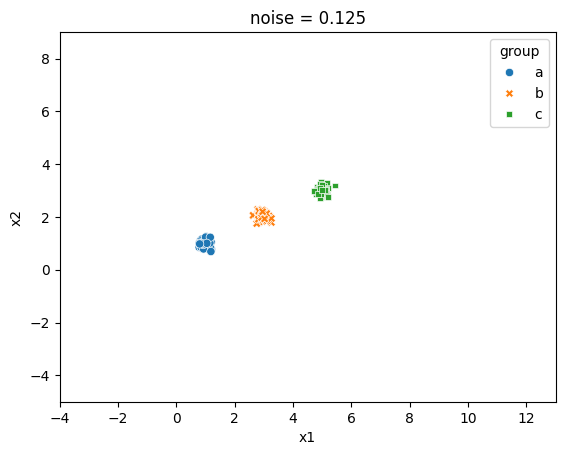

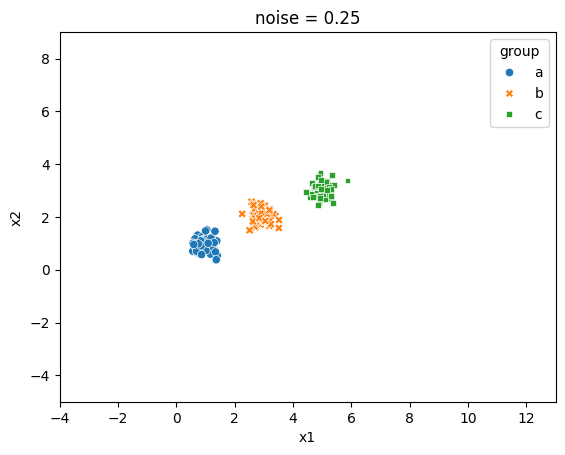

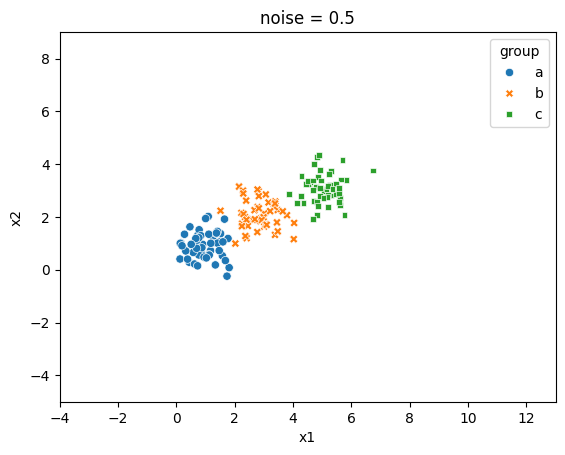

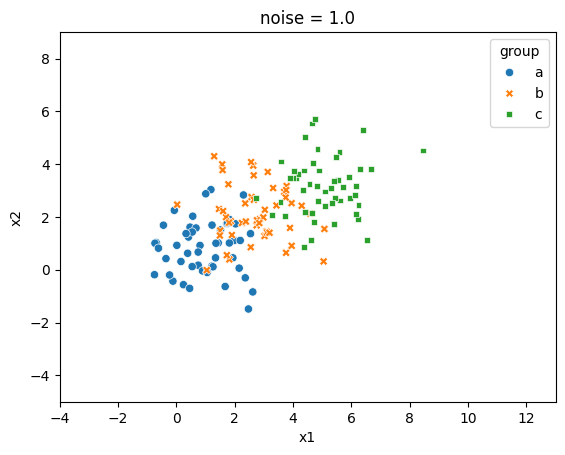

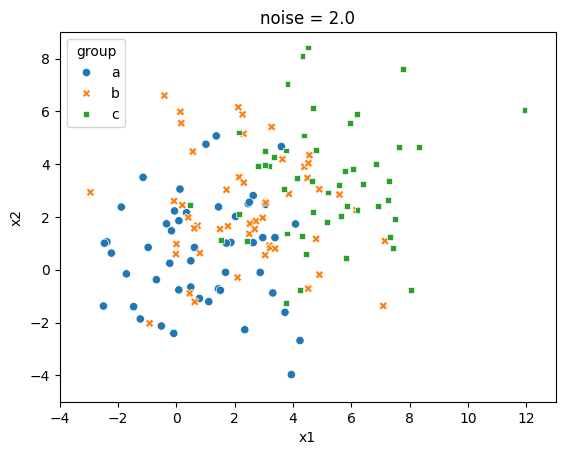

In [57]:
# Store the five datasets in a dictionary, labeled by their noise level
datasets = {
    "0.125": df0_125, "0.25": df0_25, "0.5": df0_5, "1.0": df1_0, "2.0": df2_0
}

# Making one scatterplot per dataset
for noise, df in datasets.items():
    plt.figure()
    ax = sns.scatterplot(data=df, x="x1", y="x2", hue="group", style="group")
    ax.set(title=f"noise = {noise}", xlim=(-4, 13), ylim=(-5, 9))

At noise 0.125 and 0.25, the three groups are tight and clearly separated. At 0.5 they get wider and start to touch, but the three centers are still visible. At 1.0 they overlap heavily, and by 2.0 they look like one big cloud. The cluster centers stay in the same place while the spread grows, so once the spread is about as big as the distance between centers, the groups blend together.

**Q1.3**

Text(0, 0.5, 'SSE')

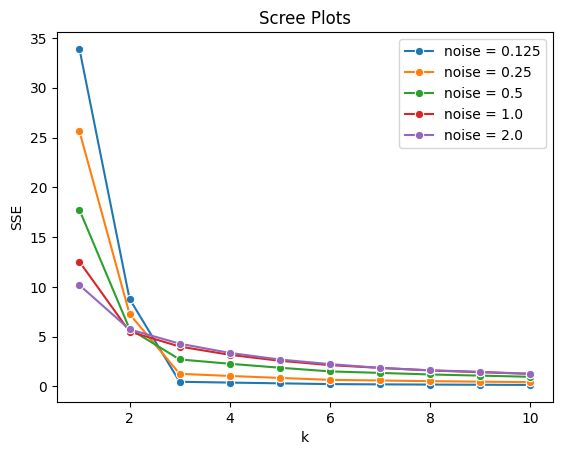

In [58]:
# Try k = 1 through 10 clusters
ks = np.arange(1, 11)

# Make a scree curve for each dataset, all on the same plot
for noise, df in datasets.items():
    # Min-max scale x1 and x2
    unscaled = df.loc[:, ["x1", "x2"]]
    mins = unscaled.min()
    ranges = unscaled.max() - mins
    X = (unscaled - mins) / ranges
    # Fit k-means for each k and save the SSE
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]
    # Add this dataset's curve to the plot
    sns.lineplot(x=ks, y=SSE, marker="o", label=f"noise = {noise}")

# Label the combined plot
plt.title("Scree Plots")
plt.xlabel("k")
plt.ylabel("SSE")

I min-max scaled each dataset and put all five scree curves on the same plot. After scaling, the low-noise datasets have the highest SSE at k = 1, because scaling divides each dataset by its range and the noisy ones get squeezed more. So I focused on the shape of each curve instead of its height. For noise 0.125 and 0.25 there is a sharp elbow at k = 3, where the SSE drops a lot and then flattens. At 0.5 the elbow is still at k = 3 but softer. At 1.0 the curve bends gradually, so 2 or 3 could both be argued. At 2.0 there is no elbow, and the SSE just decreases smoothly. As noise increases the elbow fades and picking k becomes a judgment call, even though there are always three real groups.

**Q1.4**

SSE always decreases as k increases, but the elbow shows where the drops get small. When k is less than the real number of groups, some centroid sits between two groups, so adding a cluster splits them and SSE drops a lot. Once k matches the real number of groups, extra clusters only split the noise within a group, so SSE barely drops. In my simulation, at noise 0.125 the groups are far apart compared to their spread, so k = 3 removes almost all the SSE and there’s a sharp elbow. At noise 2.0 the groups overlap so much that splitting them helps about as much as splitting noise, so SSE decreases smoothly with no elbow.

**Q2.1**

In [59]:
# Load the SIPRI data from the uploaded file
df = pd.read_csv("SIPRI Military Expenditure Database.csv")

# Keep 2020, drop missing values, remove unneeded columns, and use country names as the index
df = (
    df.loc[df["Year"] == 2020, :]
    .dropna()
    .drop(columns=["index", "Year"])
    .set_index("Country")
    .copy()
)

# Check the number of countries and summarize the variables
print(df.shape)
display(df.describe())

# Min-max normalize all four variables so each ranges from 0 to 1
unscaled = df.loc[:, ["Spending (2020 USD)", "Spending per Capita",
                      "Percent of Government Spending", "Percent of GDP"]]
mins = unscaled.min()
ranges = unscaled.max() - mins
df_scaled = (unscaled - mins) / ranges

# Checking that every variable now goes from 0 to 1
df_scaled.agg(["min", "max"])

(148, 4)


,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.000000,148.000000,148.000000
mean,13153.747670,0.019619,0.061510,268.264494
std,68005.236120,0.015033,0.046207,430.434878
min,8.622460,0.000054,0.004896,0.580129
25%,204.877177,0.010413,0.031352,20.553464
50%,959.535443,0.015324,0.047402,81.506703
75%,5289.998320,0.024327,0.084681,326.267753
max,778397.200000,0.098470,0.303027,2520.398541


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


After filtering to 2020 and dropping missing values, I got 148 countries. All four variables are numeric, so no major cleaning was needed. I dropped the index and Year columns and set Country as the index. Zimbabwe’s values look like an error, and dropping missing rows removed big spenders like Qatar and the UAE. The data is very skewed, with the US spending about 778 billion USD while the median country spends under 1 billion USD. Since the variables are on very different scales, I min-max normalized them so each ranges from 0 to 1.

**Q2.2**

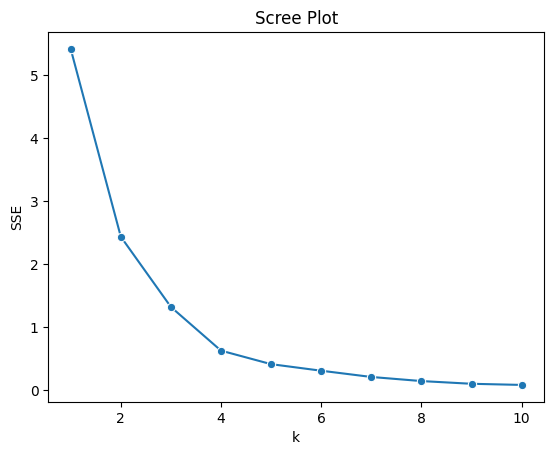

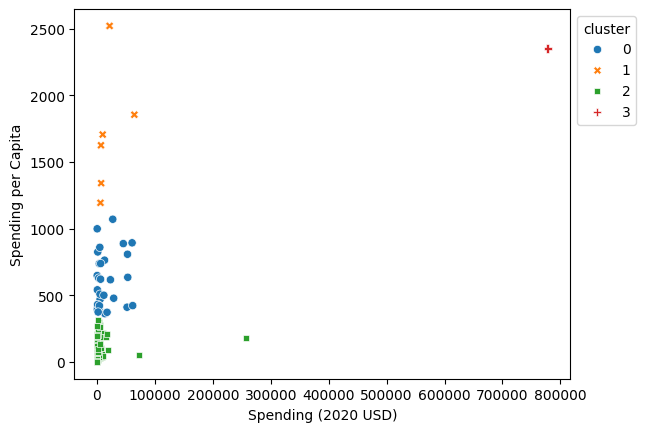

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Percent of GDP            ... Percent of Government Spending  \
                 count      mean  ...                            75%   
cluster                           ...                                  
0                 30.0  0.019397  ...                       0.048819   
1                  6.0  0.059781  ...                       0.164503   
2                111.0  0.017349  ...                       0.083508   
3                  1.0  0.037179  ...                       0.081976   

                  Spending per Capita                                        \
              max               count         mean         std          min   
cluster                                                                       
0        0.114776                30.0   607.478618  206.928757   362.467076   
1        0.225050                 6.0  1706.721916  466.375705  1193.598730   
2        0.303027               111.0    80.061470   83.501824     0.580129   
3        0.081976                 1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858  

[4 rows x 32 columns]

,Spending (2020 USD),Spending per Capita,cluster
Country,,,
Israel,21816.569767,2520.398541,1
Kuwait,6941.042345,1625.156250,1
Norway,7269.880030,1341.058851,1
Oman,6095.708713,1193.598730,1
Saudi Arabia,64558.400000,1854.380422,1
Singapore,9978.571429,1705.738706,1
United States of America,778397.200000,2351.631858,3


United States cluster: 3
China cluster: 2


In [60]:
# Use the two spending variables, already normalized in 2.1
features = ["Spending (2020 USD)", "Spending per Capita"]
X = df_scaled.loc[:, features]

# Scree plot for k = 1 through 10
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, marker="o").set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

# Fit k-means with 4 clusters and plot the clusters
model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_
ax = sns.scatterplot(
    data=df, x="Spending (2020 USD)", y="Spending per Capita",
    hue="cluster", style="cluster", palette="tab10"
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

# Summarize each cluster
display(df.groupby("cluster").describe())

# Show the countries in the small clusters
sizes = df["cluster"].value_counts()
small = sizes[sizes < 10].index
display(df.loc[df["cluster"].isin(small), features + ["cluster"]])

# Check where the US and China ended up
print("United States cluster:", df.loc["United States of America", "cluster"])
print("China cluster:", df.loc["China", "cluster"])

The scree plot drops a lot until k = 4 and then flattens, so I used 4 clusters. The United States is in its own cluster since it spends about three times as much as China. A small cluster of six countries spends the most per person, which are Israel, Saudi Arabia, Singapore, Kuwait, Norway and Oman. About 30 countries spend around 400 to 1000 USD per person, and the other 111 countries spend less than about 300. Other than the US, the clusters are based almost entirely on spending per capita, because the US is such an outlier that every other country gets squished near zero on total spending. China shows this, since it is the second biggest spender but lands in the lowest cluster because of its large population.

**Q2.3**

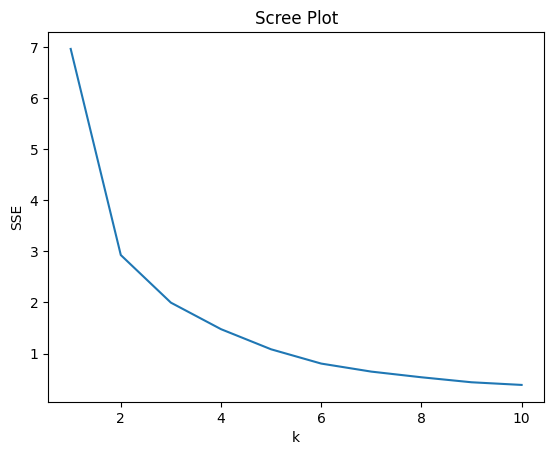

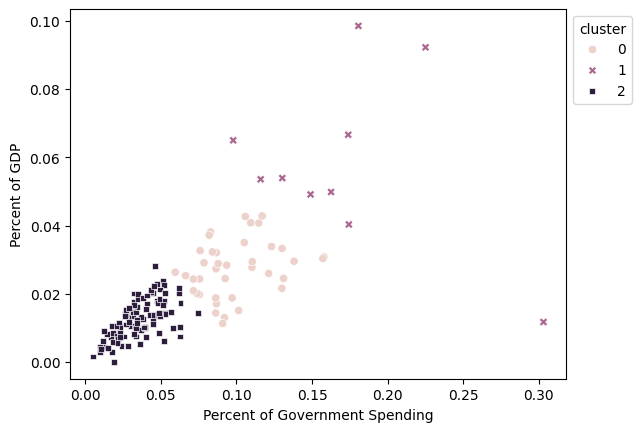

Spending (2020 USD)                                           \
                      count          mean            std         min   
cluster                                                                
0                      39.0  27387.150069  124489.244263   44.348098   
1                      10.0  12514.955945   19365.712246  633.960400   
2                      99.0   7611.174172   27958.296403    8.622460   

                                                               Percent of GDP  \
                 25%          50%           75%            max          count   
cluster                                                                         
0         310.624359  1157.372367   5786.787259  778397.200000           39.0   
1        2101.377796  6518.375529  10222.946276   64558.400000           10.0   
2         121.641398   567.650747   3910.107493  257973.429834           99.0   

                   ... Percent of Government Spending            \
             mean  ...                            75%       max   
cluster            ...                                            
0        0.027412  ...                       0.112633  0.157918   
1        0.058071  ...                       0.179081  0.303027   
2        0.012664  ...                       0.047402  0.074624   

        Spending per Capita                                                 \
                      count        mean         std        min         25%   
cluster                                                                      
0                      39.0  271.264618  484.849023   5.674383   24.603244   
1                      10.0  817.301890  904.866469  47.056944  204.615548   
2                      99.0  211.624304  278.496227   0.580129   16.487333   

                                               
                50%          75%          max  
cluster                                        
0        115.732975   209.705770  2351.631858  
1        221.050502  1517.266870  2520.398541  
2         72.164472   367.649743  1341.058851  

[3 rows x 32 columns]

,Percent of Government Spending,Percent of GDP,cluster
Country,,,
Algeria,0.173924,0.066600,1
Armenia,0.162572,0.049827,1
Azerbaijan,0.130339,0.053905,1
Belarus,0.303027,0.011742,1
Israel,0.116052,0.053553,1
Jordan,0.149025,0.049121,1
Kuwait,0.097882,0.064961,1
Oman,0.180654,0.098470,1
Pakistan,0.174362,0.040317,1


United States of America cluster: 0
China cluster: 2
Russia cluster: 0
India cluster: 0
Norway cluster: 2
United States Percent of GDP: 0.0371788506411201


In [61]:
# Use the two percent variables, already normalized in 2.1
features = ["Percent of Government Spending", "Percent of GDP"]
X = df_scaled.loc[:, features]

# Scree plot for k = 1 through 10
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

# Fit k-means with 3 clusters and plot the clusters
model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_
ax = sns.scatterplot(
    data=df, x="Percent of Government Spending", y="Percent of GDP",
    hue="cluster", style="cluster"
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

# Summarize each cluster
display(df.groupby("cluster").describe())

# Show the countries in the smallest cluster
sizes = df["cluster"].value_counts()
display(df.loc[df["cluster"] == sizes.idxmin(), features + ["cluster"]])

# Checking where some key countries ended up
for country in ["United States of America", "China", "Russia", "India", "Norway"]:
    print(country, "cluster:", df.loc[country, "cluster"])

# Check the US share of GDP spent on the military
print("United States Percent of GDP:", df.loc["United States of America", "Percent of GDP"])

The scree plot drops the most at k = 2 and a little more at k = 3 before flattening, so I used 3 clusters. These results are very different from part 2. Part 2 grouped countries by how much they spend, which mostly reflected wealth, while this part groups them by how much of their GDP and budget goes to the military. The US is no longer alone and is in the middle cluster with Russia and India, since its spending is only about 3.7% of its GDP. China is the second biggest spender but lands in the lowest cluster. Norway was with Saudi Arabia and Israel in part 2, but now it is in the lowest cluster while they are in the highest. The highest cluster is mostly countries in tense regions like the Middle East and the Caucasus. The clusters are also more balanced since there is no single outlier squishing everyone together.

**Q2.4**

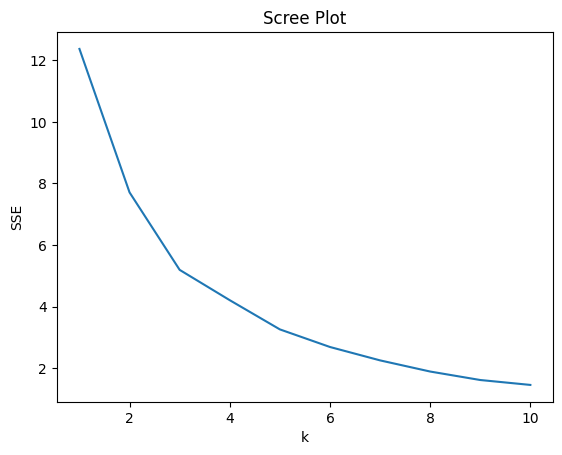

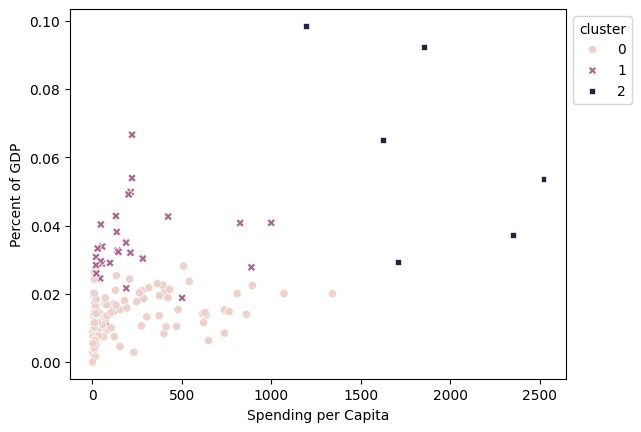

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Percent of GDP            ... Percent of Government Spending  \
                 count      mean  ...                            75%   
cluster                           ...                                  
0                111.0  0.013419  ...                       0.050505   
1                 31.0  0.033492  ...                       0.134663   
2                  6.0  0.062634  ...                       0.164503   

                  Spending per Capita                                        \
              max               count         mean         std          min   
cluster                                                                       
0        0.092044               111.0   196.926833  267.788506     0.580129   
1        0.303027                31.0   212.689100  257.841988    18.297119   
2        0.225050                 6.0  1875.150751  489.800206  1193.598730   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          14.880549    67.083417   295.296094  1341.058851  
1          46.485917   135.459845   217.333791   998.966186  
2        1645.301864  1780.059564  2227.318999  2520.398541  

[3 rows x 32 columns]

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,cluster
Country,,,,,
Israel,21816.569767,2520.398541,0.116052,0.053553,2
Kuwait,6941.042345,1625.156250,0.097882,0.064961,2
Oman,6095.708713,1193.598730,0.180654,0.098470,2
Saudi Arabia,64558.400000,1854.380422,0.225050,0.092211,2
Singapore,9978.571429,1705.738706,0.110489,0.029429,2
United States of America,778397.200000,2351.631858,0.081976,0.037179,2


United States of America cluster: 2
China cluster: 0
Russia cluster: 1
India cluster: 1
Pakistan cluster: 1
Ukraine cluster: 1
United Kingdom cluster: 0
Germany cluster: 0
Japan cluster: 0
Norway cluster: 0


In [62]:
# Use all four variables, already normalized in 2.1
features = ["Spending (2020 USD)", "Spending per Capita",
            "Percent of Government Spending", "Percent of GDP"]
X = df_scaled.loc[:, features]

# Scree plot for k = 1 through 10
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

# Fit k-means with 3 clusters and plot two of the variables
model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_
ax = sns.scatterplot(
    data=df, x="Spending per Capita", y="Percent of GDP",
    hue="cluster", style="cluster"
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

# Summarizing each cluster
display(df.groupby("cluster").describe())

# Show the countries in the smallest cluster
sizes = df["cluster"].value_counts()
display(df.loc[df["cluster"] == sizes.idxmin(), features + ["cluster"]])

# Check where some key countries ended up
for country in ["United States of America", "China", "Russia", "India",
                "Pakistan", "Ukraine", "United Kingdom", "Germany", "Japan", "Norway"]:
    print(country, "cluster:", df.loc[country, "cluster"])

The scree plot has no sharp elbow, but the big drops end around k = 3, so I used 3 clusters. The results look like a mix of parts 2 and 3. The smallest cluster has six countries that are high on both per-person spending and share of GDP, which are the US, Saudi Arabia, Israel, Kuwait, Oman and Singapore. The second cluster has 31 countries like Russia, India, Pakistan and Ukraine that spend a large share of GDP but not much per person. The largest cluster has 111 countries that spend a small share, including China, the UK, Germany, Japan and Norway. Compared to part 2, the US is no longer alone and is grouped with other wealthy high spenders. Compared to part 3, it moves away from Russia and India because it spends much more per person. Total spending still barely matters, since the US pushes every other country close to zero after scaling.

**Q2.5**

I think k-means found some useful patterns, but with limits. It was helpful for showing the difference between how much money a country spends on its military and how much of its economy and budget that spending takes up. Seeing the US, China and Norway land in different clusters depending on which variables I used showed that the answer to which countries spend the most depends a lot on how you measure it. The higher-spending clusters in parts 3 and 4 also picked out countries in tense regions like the Middle East and Eastern Europe, which makes sense. However, the US was such a big outlier that after min-max scaling total spending barely mattered for any other country. The elbows in parts 3 and 4 were also not very clear, so the number of clusters was partly a judgment call, like the noisy datasets in Q1. The biggest clusters also mixed together very different countries, like rich European countries and poor African countries. So k-means was useful for exploring the data and spotting outliers, but I wouldn’t treat the clusters as real categories of countries.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [63]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]